# Housing loan screening: exploratory data analysis

This notebook explores only the locked 80% training partition. The raw file is hash-verified; no imputer, scaler, encoder or sampler is fitted before the split. Missing numeric observations are omitted by plotting functions, while missing categorical groups are shown explicitly. Monetary values use dataset units. This notebook can be run from the project root or notebooks folder.


In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / 'src').exists():
    project_root = project_root.parent
if not (project_root / 'src').exists():
    raise RuntimeError('Open this notebook from the project root or notebooks directory.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from IPython.display import Image, display
from src.eda import training_frame, generate_figures, key_insights
frame = training_frame()
print(f'Training observations: {len(frame)}; holdout excluded from all EDA.')
display(frame.drop(columns=['Loan_ID']).head())
figure_paths = generate_figures(frame)


Training observations: 491; holdout excluded from all EDA.


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Approved,Loan_Status
154,Male,No,0,Graduate,No,3254,0.0,50.0,360.0,1.0,Urban,1,Approved
239,Male,Yes,1,Graduate,No,3315,0.0,96.0,360.0,1.0,Semiurban,1,Approved
448,Male,Yes,2,Graduate,No,3340,1710.0,150.0,360.0,0.0,Rural,0,Rejected
471,Male,Yes,1,Not Graduate,No,2653,1500.0,113.0,180.0,0.0,Rural,0,Rejected
273,Male,Yes,0,Graduate,No,2620,2223.0,150.0,360.0,1.0,Semiurban,1,Approved


## Figure 1: 01 target


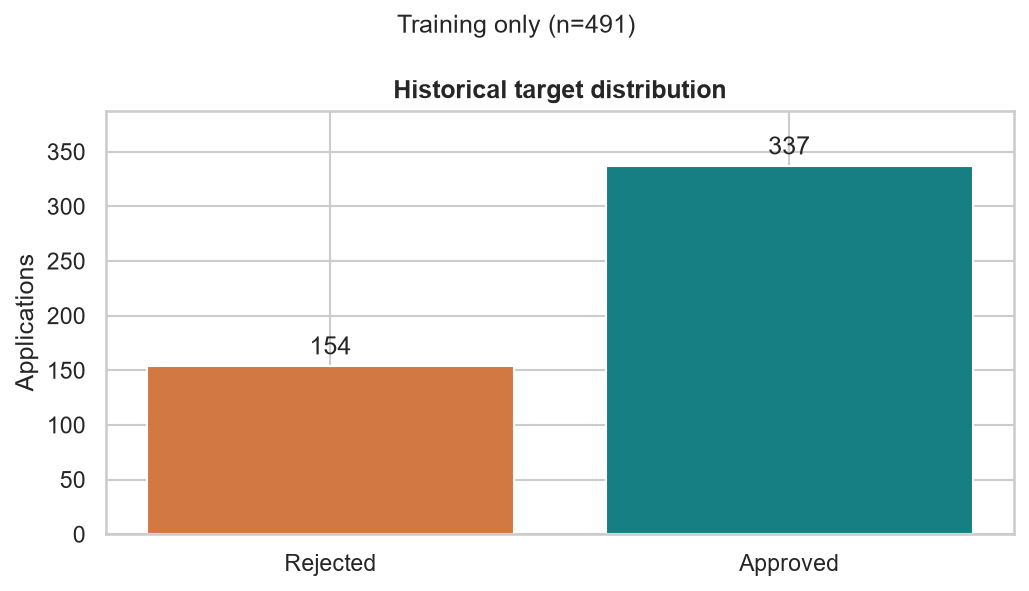

In [2]:
display(Image(filename=str(figure_paths[0]), width=1000))


## Figure 2: 02 income histograms


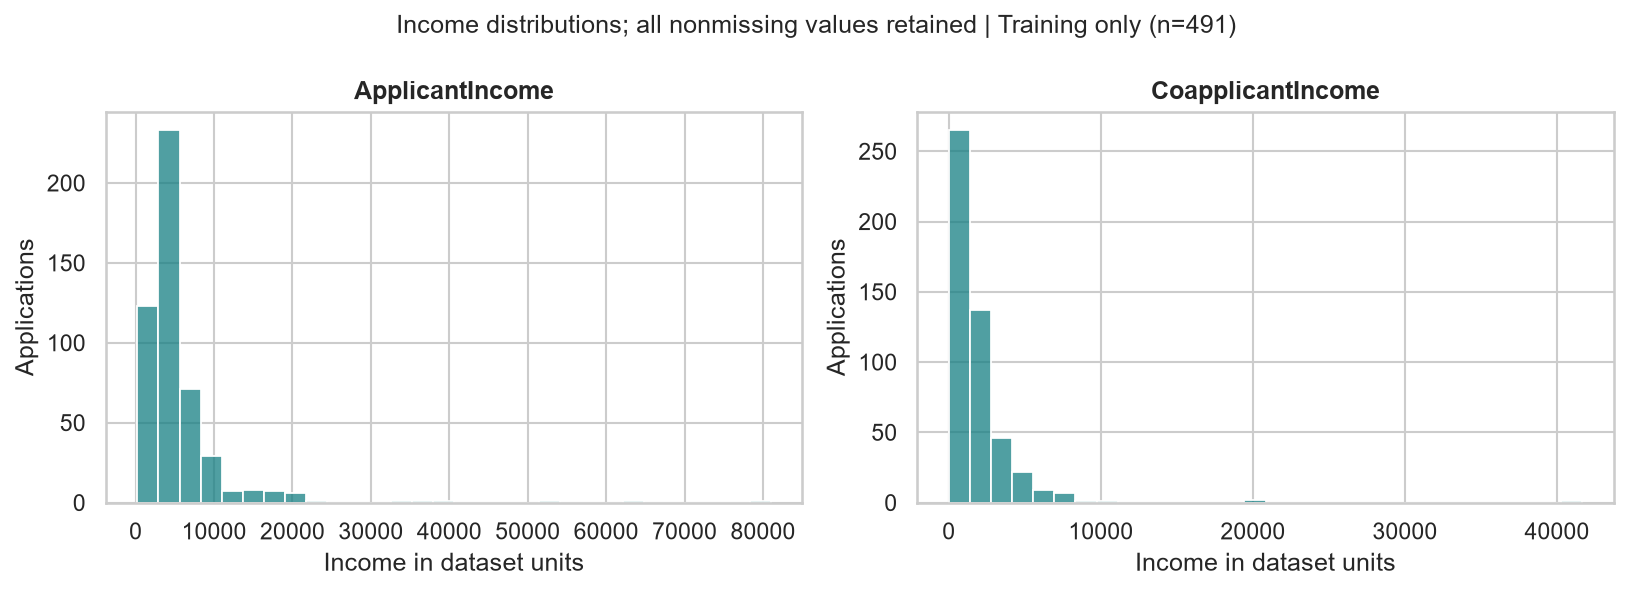

In [3]:
display(Image(filename=str(figure_paths[1]), width=1000))


## Figure 3: 03 loan distribution


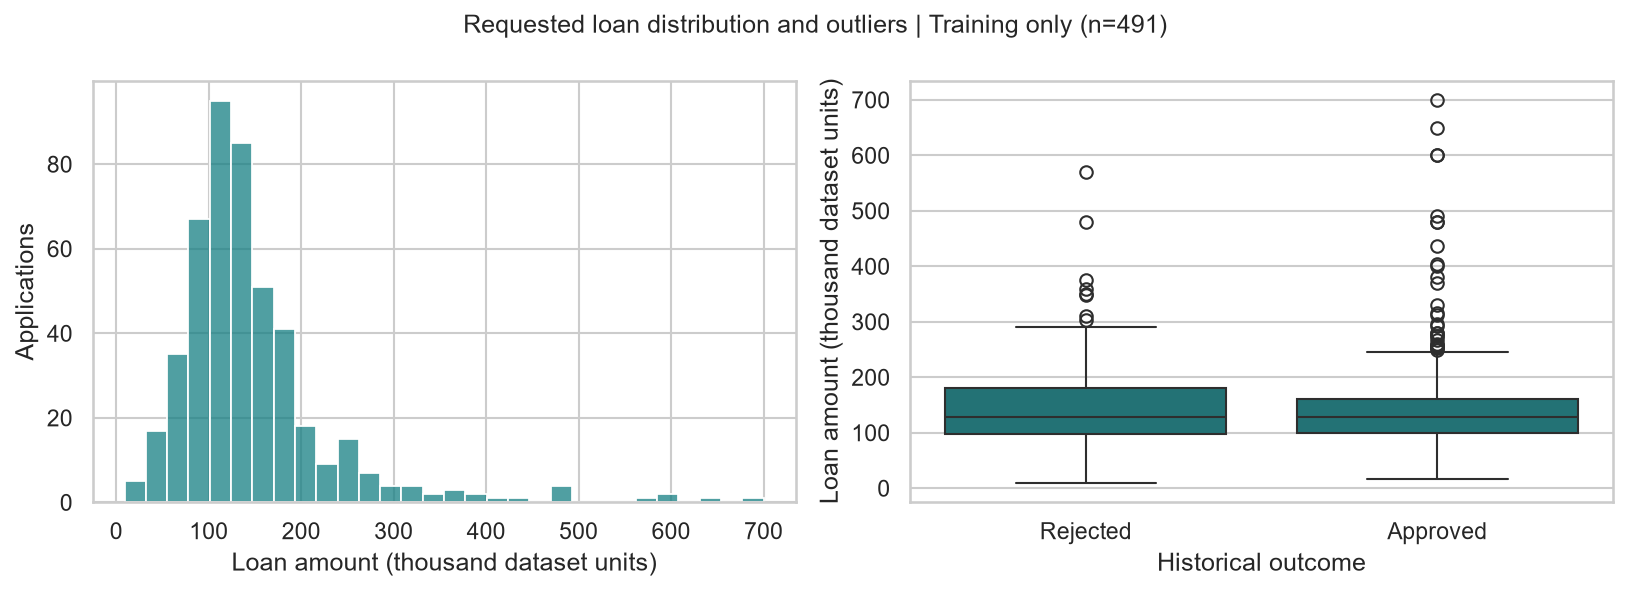

In [4]:
display(Image(filename=str(figure_paths[2]), width=1000))


## Figure 4: 04 credit history


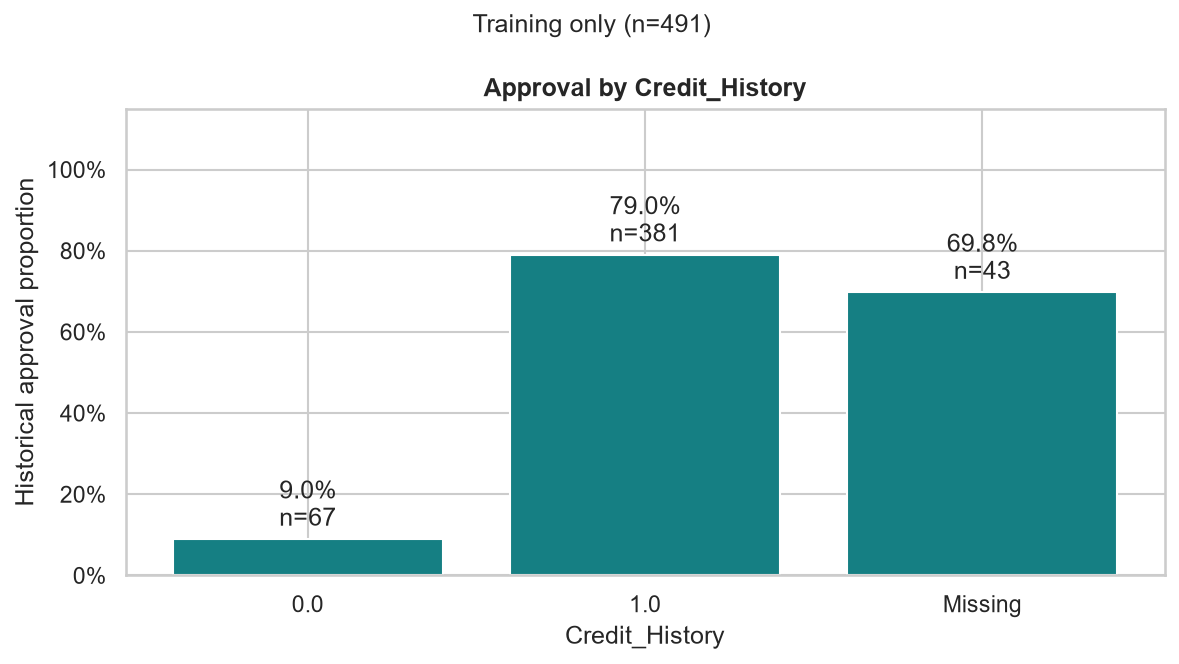

In [5]:
display(Image(filename=str(figure_paths[3]), width=1000))


## Figure 5: 05 property area


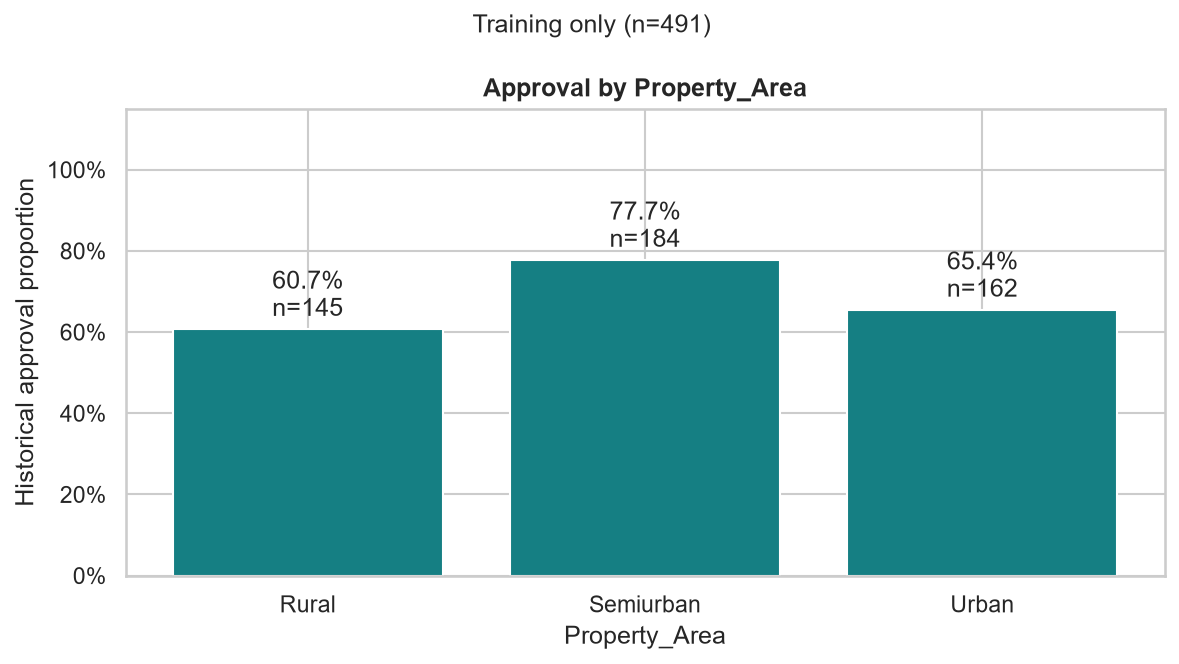

In [6]:
display(Image(filename=str(figure_paths[4]), width=1000))


## Figure 6: 06 education


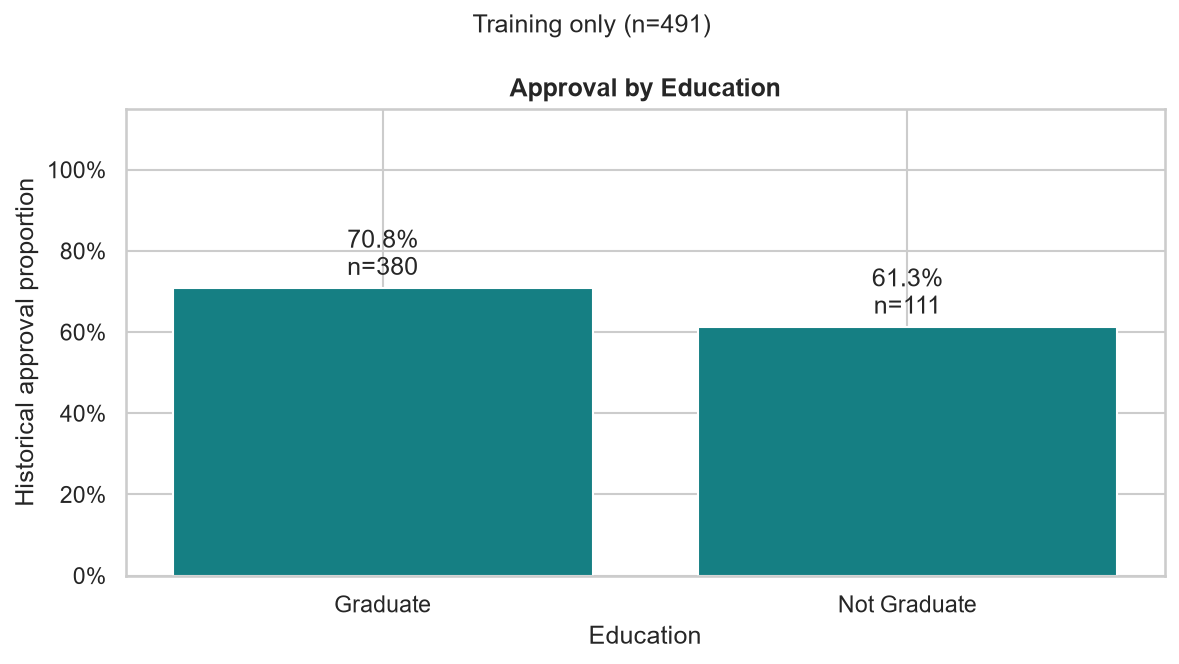

In [7]:
display(Image(filename=str(figure_paths[5]), width=1000))


## Figure 7: 07 married


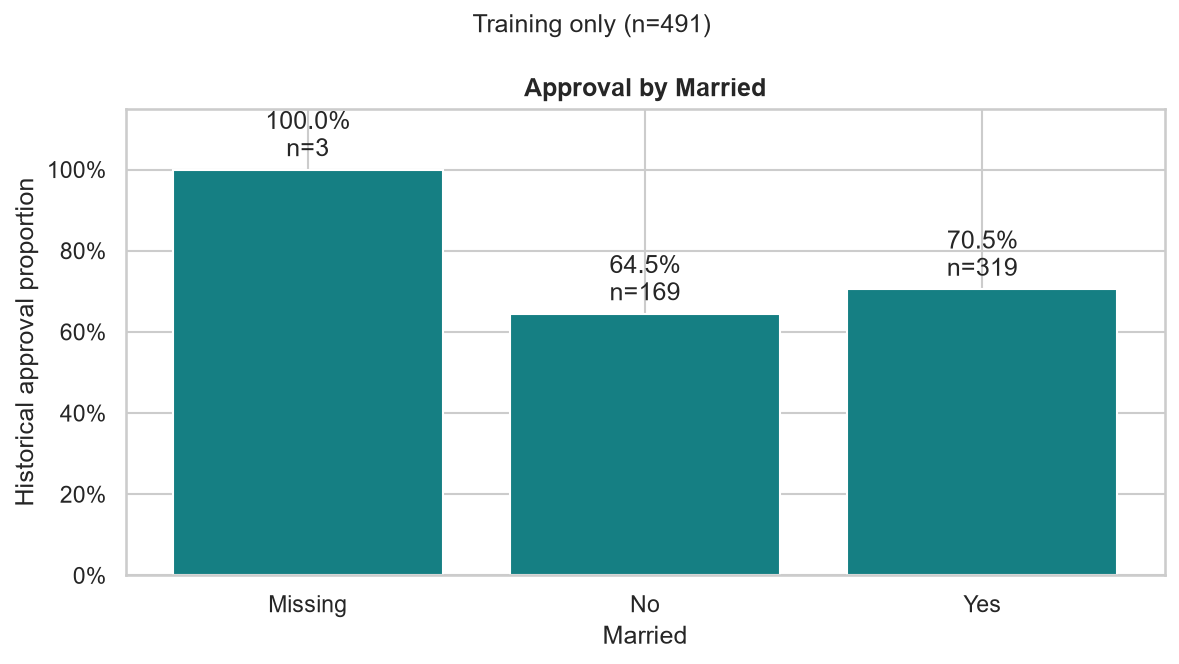

In [8]:
display(Image(filename=str(figure_paths[6]), width=1000))


## Figure 8: 08 self employed


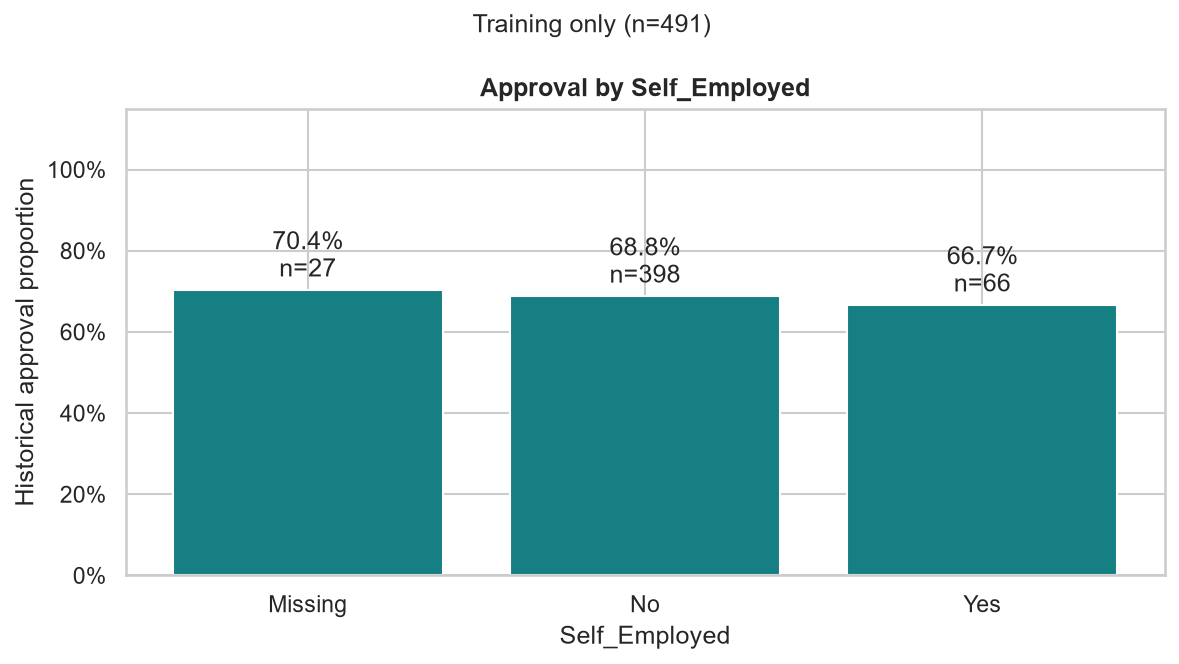

In [9]:
display(Image(filename=str(figure_paths[7]), width=1000))


## Figure 9: 09 income boxplots


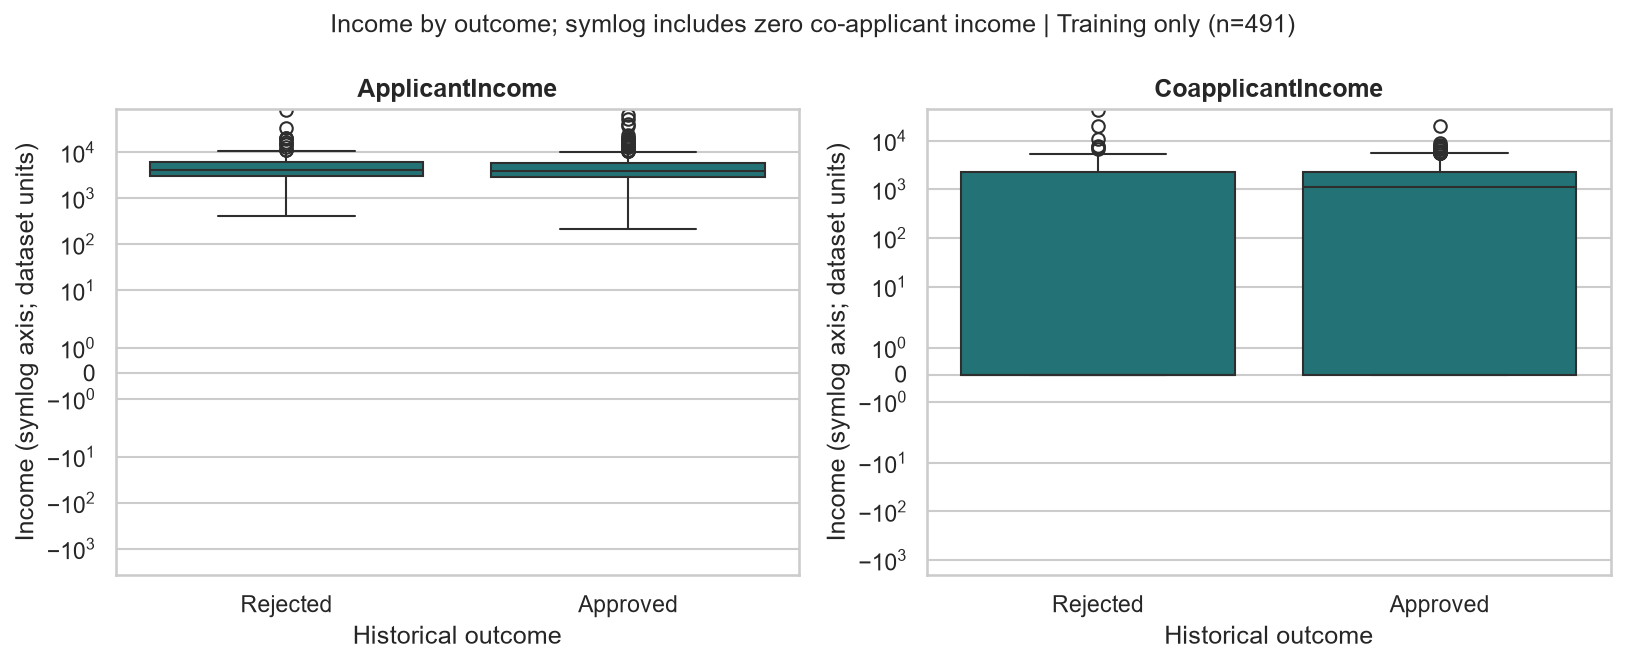

In [10]:
display(Image(filename=str(figure_paths[8]), width=1000))


## Figure 10: 10 correlations


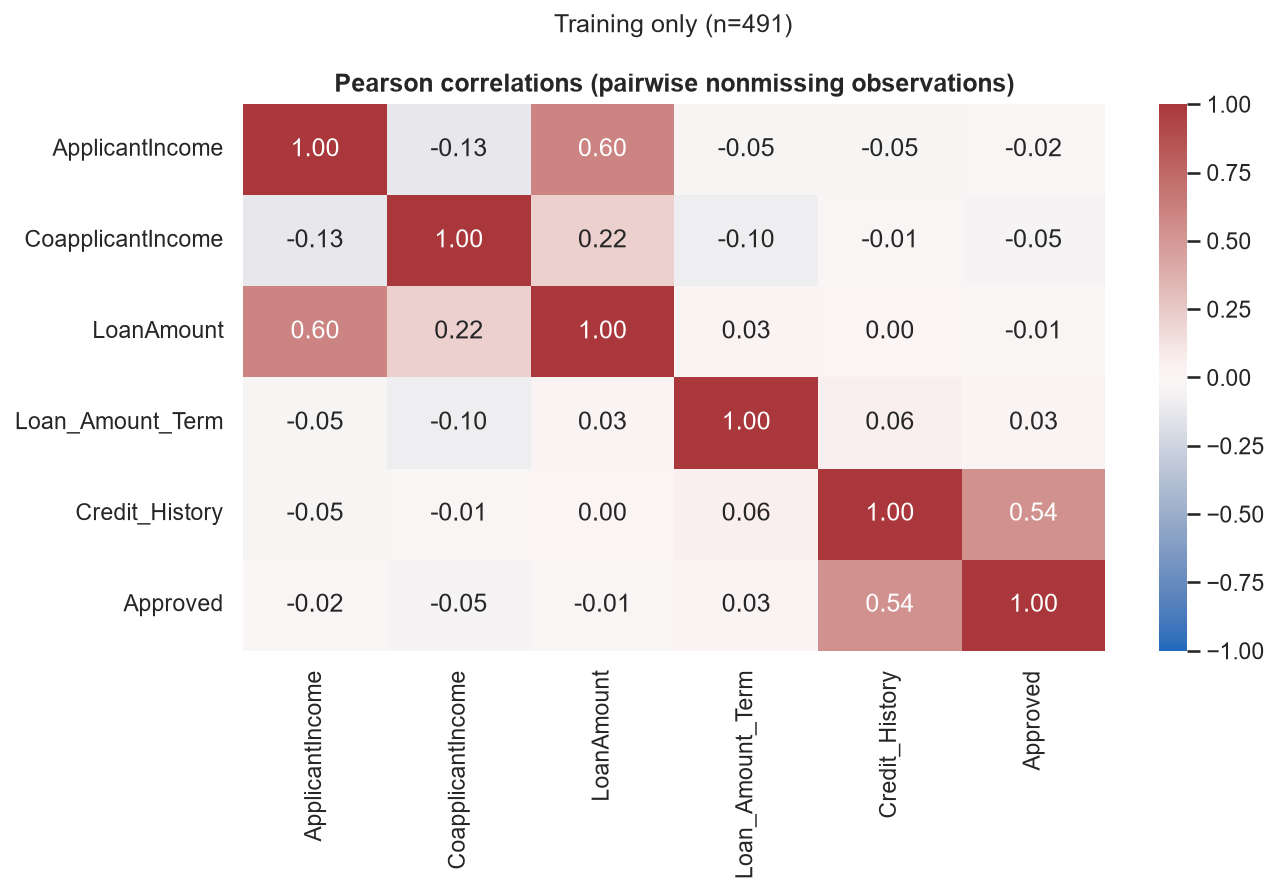

In [11]:
display(Image(filename=str(figure_paths[9]), width=1000))


In [12]:
# Recalculate the prose evidence if observations change.
for insight in key_insights(frame):
    print(insight + '\n')


The training partition contains 491 applications: 337 approved (68.6%) and 154 rejected. An always-approve baseline therefore has 68.6% training accuracy.

Observed credit-history groups: 0.0: 9.0% approved (n=67); 1.0: 79.0% approved (n=381); Missing: 69.8% approved (n=43). These are historical label associations, not repayment probabilities.

Observed approval rates by property area: Rural: 60.7% (n=145); Semiurban: 77.7% (n=184); Urban: 65.4% (n=162). Group composition may explain part of these differences.

Applicant income has median 3859.00, mean 5530.00, and maximum 81000.00 dataset units. Log1p features retain these observations while reducing scale differences.

The training loan amount has median 128.00 and maximum 700.00 thousand dataset units, with 20 missing values. Plots omit missing numeric values; fold-local median imputation handles them during modeling.

Credit_History has 43 missing training values; Self_Employed has 27. Missing groups remain visible in approval-rate

## Key Insights

- The training partition contains 491 applications: 337 approved (68.6%) and 154 rejected. An always-approve baseline therefore has 68.6% training accuracy.

- Observed credit-history groups: 0.0: 9.0% approved (n=67); 1.0: 79.0% approved (n=381); Missing: 69.8% approved (n=43). These are historical label associations, not repayment probabilities.

- Observed approval rates by property area: Rural: 60.7% (n=145); Semiurban: 77.7% (n=184); Urban: 65.4% (n=162). Group composition may explain part of these differences.

- Applicant income has median 3859.00, mean 5530.00, and maximum 81000.00 dataset units. Log1p features retain these observations while reducing scale differences.

- The training loan amount has median 128.00 and maximum 700.00 thousand dataset units, with 20 missing values. Plots omit missing numeric values; fold-local median imputation handles them during modeling.

- Credit_History has 43 missing training values; Self_Employed has 27. Missing groups remain visible in approval-rate plots.

- Income and loan distributions and group differences are descriptive. Neither this EDA nor SHAP can establish causal effects, fair treatment, repayment performance or NPA reduction.
